In [1]:
# Imports and configuration
import warnings
warnings.filterwarnings('ignore')
import re, time, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from dtaidistance import dtw
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from statsmodels.tsa.stattools import coint
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from pykalman import KalmanFilter

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

# Data
DATA_START   = '2000-01-01'   # one buffer year so the 52-week rolling Sharpe covers all of Train
END_DATE     = '2026-01-01'
SNAPSHOT     = '2001-01-01'   # constituent snapshot date
BENCHMARK    = '^SP500TR'          # auto-adjusted, so dividends are included
RF_TICKER    = '^IRX'         # 13-week T-bill yield, annualized percent
FALLBACK_RF  = 0.0            # used only if ^IRX fails to download

# Periods
TRAIN_START, TRAIN_END = '2001-01-01', '2008-12-31'   # 8 years
VAL_START,   VAL_END   = '2009-01-01', '2016-12-31'   # 8 years
TEST_START,  TEST_END  = '2017-01-01', '2025-12-31'   # 9 years

# Clustering
ROLLING_WINDOW = 52
K_VALUES       = [2, 4, 7]
K_COINT        = 7      # pair formation uses k=7 clusters to keep the candidate pool tractable
N_CORES        = 10     # only used by the multiprocess fallback for OCP

# Strategy parameters 
ZSCORE_WINDOW  = 52
VOL_WINDOW     = 26
VOL_THRESHOLD  = 1.5
HIGH_VOL_ENTRY = 2.25
LOW_VOL_ENTRY  = 1.25
STANDARD_ENTRY = 1.75
EXIT_THRESHOLD = 0.5
STOP_LOSS      = 3.25

CANDIDATE_MULTIPLIERS = [0.60, 0.75, 0.85, 1.00, 1.15, 1.25]
ACTIVITY_FLOOR        = 0.50
COST_LEVELS_BPS       = [0, 5, 10, 20]

N_BOOT, BLOCK_SIZE, BOOT_SEED = 5000, 8, 42

# calendar version (robustness). Everything outside the windows is bull.
BEAR_WINDOWS_PRIMARY = [('2018-09-20', '2018-12-24'),
                        ('2020-02-19', '2020-03-23'),
                        ('2022-01-03', '2022-10-12')]
BEAR_WINDOWS_ALT     = [('2018-10-01', '2018-12-31'),
                        ('2020-02-19', '2020-03-23'),
                        ('2022-01-03', '2022-10-12')]

METHODS = ['DTW', 'OCP', 'CORR']
LABELS  = {'DTW': 'DTW-Clustering', 'OCP': 'OCP-Clustering',
           'CORR': 'Correlation Pairs', 'Naive': 'Naive Buy-and-Hold'}
COLORS  = {'DTW': '#1f77b4', 'OCP': '#ff7f0e', 'CORR': '#2ca02c', 'Naive': '#7f7f7f'}
TAG     = 'sp500_25y'

def n_years(a, b):
    return round((pd.Timestamp(b) - pd.Timestamp(a)).days / 365.25)

print('DTW vs OCP vs Correlation Pairs vs Naive, S&P 500 25-Year Framework')
print(f'Train: {TRAIN_START} to {TRAIN_END} ({n_years(TRAIN_START, TRAIN_END)} years)')
print(f'Val:   {VAL_START} to {VAL_END} ({n_years(VAL_START, VAL_END)} years)')
print(f'Test:  {TEST_START} to {TEST_END} ({n_years(TEST_START, TEST_END)} years)')

DTW vs OCP vs Correlation Pairs vs Naive, S&P 500 25-Year Framework
Train: 2001-01-01 to 2008-12-31 (8 years)
Val:   2009-01-01 to 2016-12-31 (8 years)
Test:  2017-01-01 to 2025-12-31 (9 years)


In [2]:
# S&P 500 constituents as of the snapshot date (point-in-time membership list)
hist_url = ('https://raw.githubusercontent.com/fja05680/sp500/master/'
            'S%26P%20500%20Historical%20Components%20%26%20Changes.csv')
hist = pd.read_csv(hist_url)
hist['date'] = pd.to_datetime(hist['date'])

target_date  = pd.Timestamp(SNAPSHOT)
snapshot_row = hist[hist['date'] <= target_date].sort_values('date').iloc[-1]
raw_tickers  = sorted(t.strip() for t in snapshot_row['tickers'].split(','))

suffix_pattern = re.compile(r'-\d{6}$')   # dataset's own delisting-date suffix
universe = sorted(set(suffix_pattern.sub('', t).replace('.', '-') for t in raw_tickers))

n_suffixed = sum(1 for t in raw_tickers if suffix_pattern.search(t))
print(f'Using snapshot date: {snapshot_row["date"].date()}')
print(f'Tickers with a delisting-date suffix in the source data: {n_suffixed}')
print(f'S&P 500 constituents as of {target_date.date()}: {len(universe)} stocks')

Using snapshot date: 2000-12-29
Tickers with a delisting-date suffix in the source data: 204
S&P 500 constituents as of 2001-01-01: 492 stocks


In [3]:
# Prices: daily download, resampled to true Wednesday closes
def to_close_frame(raw):
    close = raw['Close'] if isinstance(raw.columns, pd.MultiIndex) else raw[['Close']]
    return close if isinstance(close, pd.DataFrame) else close.to_frame()

print(f'Downloading daily prices for {len(universe)} stocks...')
raw = yf.download(universe, start=DATA_START, end=END_DATE, interval='1d',
                  auto_adjust=True, progress=True, threads=True)
daily = to_close_frame(raw)
price_data = daily.resample('W-WED').last().dropna(how='all')

before_drop = len(universe)
price_data  = price_data.ffill().dropna(axis=1)   # complete history required

TAIL_WINDOW = 10
flatlined = [t for t in price_data.columns
             if price_data[t].iloc[-TAIL_WINDOW:].nunique() == 1]
price_data = price_data.drop(columns=flatlined)

dropped_tickers = sorted(set(universe) - set(price_data.columns))
print(f'\nPrice data shape: {price_data.shape}')
print(f'Date range: {price_data.index[0].date()} to {price_data.index[-1].date()}')
print(f'Retained: {price_data.shape[1]} of {before_drop} (dropped {len(dropped_tickers)}, '
      f'of which {len(flatlined)} flatlined)')
print(f'Dropped tickers: {dropped_tickers}')

# Benchmark: S&P 500 Total Return index (dividends reinvested, no fees)
bench_raw = to_close_frame(yf.download(BENCHMARK, start=DATA_START, end=END_DATE,
                                       interval='1d', auto_adjust=True, progress=False))
bench_weekly = bench_raw.iloc[:, 0].resample('W-WED').last().reindex(price_data.index)
n_missing = int(bench_weekly.isna().sum())
print(f'\nBenchmark {BENCHMARK}: {n_missing} missing weeks before filling (should be 0)')
bench_price = bench_weekly.ffill()

try:
    irx_raw = to_close_frame(yf.download(RF_TICKER, start=DATA_START, end=END_DATE,
                                         interval='1d', auto_adjust=False, progress=False))
    irx = irx_raw.iloc[:, 0].resample('W-WED').last().reindex(price_data.index).ffill().bfill()
    rf_weekly = np.log1p(irx / 100) / 52       # weekly log risk-free rate
    print(f'T-bill loaded: mean annual yield over sample {irx.mean():.2f}%')
except Exception as e:
    rf_weekly = pd.Series(FALLBACK_RF / 52, index=price_data.index)
    print(f'^IRX download failed ({e}); using constant rf={FALLBACK_RF}')

price_data.to_csv(f'price_data_{TAG}.csv')

$JP: possibly delisted; no timezone found
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: AL"}}}
$LEG: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01) (Yahoo error = "Data doesn't exist for startDate = 946702800, endDate = 1767243600")
[                       0%                       ]  2 of 492 completed$GDT: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01) (Yahoo error = "Data doesn't exist for startDate = 946702800, endDate = 1767243600")
[                       1%                       ]  3 of 492 completedHTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: OAT"}}}
$AL: possibly delisted; no timezone found
$OAT: possibly delisted; no timezone found       ]  4 of 492 completed
$JCP: possibly delisted; no timezone found       ]  14 of 492 completed
$RDC: possibly delisted; no timezone found       ]  19 of 49


Price data shape: (1357, 236)
Date range: 2000-01-05 to 2025-12-31
Retained: 236 of 492 (dropped 256, of which 0 flatlined)
Dropped tickers: ['AABA', 'AAMRQ', 'ABI', 'ABKFQ', 'ABS', 'ABX', 'ACV', 'ADCT', 'AET', 'AGC', 'AGN', 'AL', 'ALTR', 'AM', 'ANDW', 'APC', 'APCC', 'ARNC', 'ASO', 'AT', 'AV', 'AVP', 'AW', 'AYE', 'AZA-A', 'BBBY', 'BBT', 'BCR', 'BDK', 'BEAM', 'BGEN', 'BGG', 'BHGE', 'BIG', 'BK', 'BLL', 'BLS', 'BMC', 'BMET', 'BMS', 'BNI', 'BOL', 'BR', 'BRCM', 'BSC', 'BUD', 'BVSN', 'CA', 'CBE', 'CBS', 'CCE', 'CCTYQ', 'CEG', 'CEN', 'CF', 'CFC', 'CGP', 'CHIR', 'CIN', 'CIT-A', 'CMA', 'CMVT', 'CNC', 'CNXT', 'COC-B', 'CPNLQ', 'CPQ', 'CPWR', 'CR', 'CTB', 'CTL', 'CTX', 'CTXS', 'CVG', 'DALRQ', 'DCNAQ', 'DELL', 'DG', 'DJ', 'DOW', 'DPHIQ', 'DYN', 'EC', 'EDS', 'EKDKQ', 'EMC', 'ENRNQ', 'ETS', 'FBF', 'FDC', 'FLR', 'FRX', 'G', 'GAS', 'GDT', 'GDW', 'GLK', 'GP', 'GPS', 'GPU', 'GR', 'GTW', 'GX', 'H', 'HCA', 'HCR', 'HES', 'HET', 'HI', 'HLT', 'HM', 'HNZ', 'HOT', 'HPC', 'HSH', 'INCLF', 'IPG', 'IR', 'JAVA', '

In [4]:
# 52-week rolling Sharpe ratio in excess of the T-bill
log_returns  = np.log(price_data / price_data.shift(1))
excess_lr    = log_returns.sub(rf_weekly, axis=0)
rolling_mean = excess_lr.rolling(ROLLING_WINDOW).mean()
rolling_std  = log_returns.rolling(ROLLING_WINDOW).std()
sharpe_data  = (rolling_mean / rolling_std * np.sqrt(52)).dropna(how='all')

train_sharpe_data = sharpe_data.loc[TRAIN_START:TRAIN_END]
bad_cols = train_sharpe_data.columns[
    train_sharpe_data.isna().any() | np.isinf(train_sharpe_data).any()].tolist()
if bad_cols:
    train_sharpe_data = train_sharpe_data.drop(columns=bad_cols)
    print(f'Dropped {bad_cols} (NaN or inf rolling Sharpe in Train)')

tickers = train_sharpe_data.columns.tolist()
n = len(tickers)
print(f'Clustering universe: {n} stocks, {n*(n-1)//2:,} pairs, '
      f'{len(train_sharpe_data)} Train weeks')

Clustering universe: 236 stocks, 27,730 pairs, 418 Train weeks


In [8]:
# DTW distance matrix (Train only), absolute-difference cost to match OCP and Stübinger (2019)
from numba import njit, prange

@njit(cache=True)
def _dtw_abs(x, y):
    n, m = len(x), len(y)
    prev = np.full(m, np.inf)
    for i in range(n):
        cur = np.full(m, np.inf)
        for j in range(m):                      # DTW: any j (no causality constraint)
            if i == 0 and j == 0:
                cur[0] = abs(x[0] - y[0])
                continue
            best = np.inf
            if i > 0 and prev[j] < best:
                best = prev[j]
            if j > 0 and cur[j - 1] < best:
                best = cur[j - 1]
            if i > 0 and j > 0 and prev[j - 1] < best:
                best = prev[j - 1]
            cur[j] = abs(x[i] - y[j]) + best
        prev = cur
    return prev[m - 1]

@njit(parallel=True, cache=True)
def _dtw_matrix(X):
    n = X.shape[1]
    D = np.zeros((n, n))
    for i in prange(n):
        for j in range(i + 1, n):
            d = _dtw_abs(X[:, i], X[:, j])
            D[i, j] = d
            D[j, i] = d
    return D

X = train_sharpe_data[tickers].values.astype(np.float64)
t0 = time.time()
dtw_distance_matrix = _dtw_matrix(X)
print(f'DTW distance matrix computed in {time.time()-t0:.1f} seconds, shape {dtw_distance_matrix.shape}')
np.save(f'dtw_distance_matrix_{TAG}_train.npy', dtw_distance_matrix)

DTW distance matrix computed in 23.3 seconds, shape (236, 236)


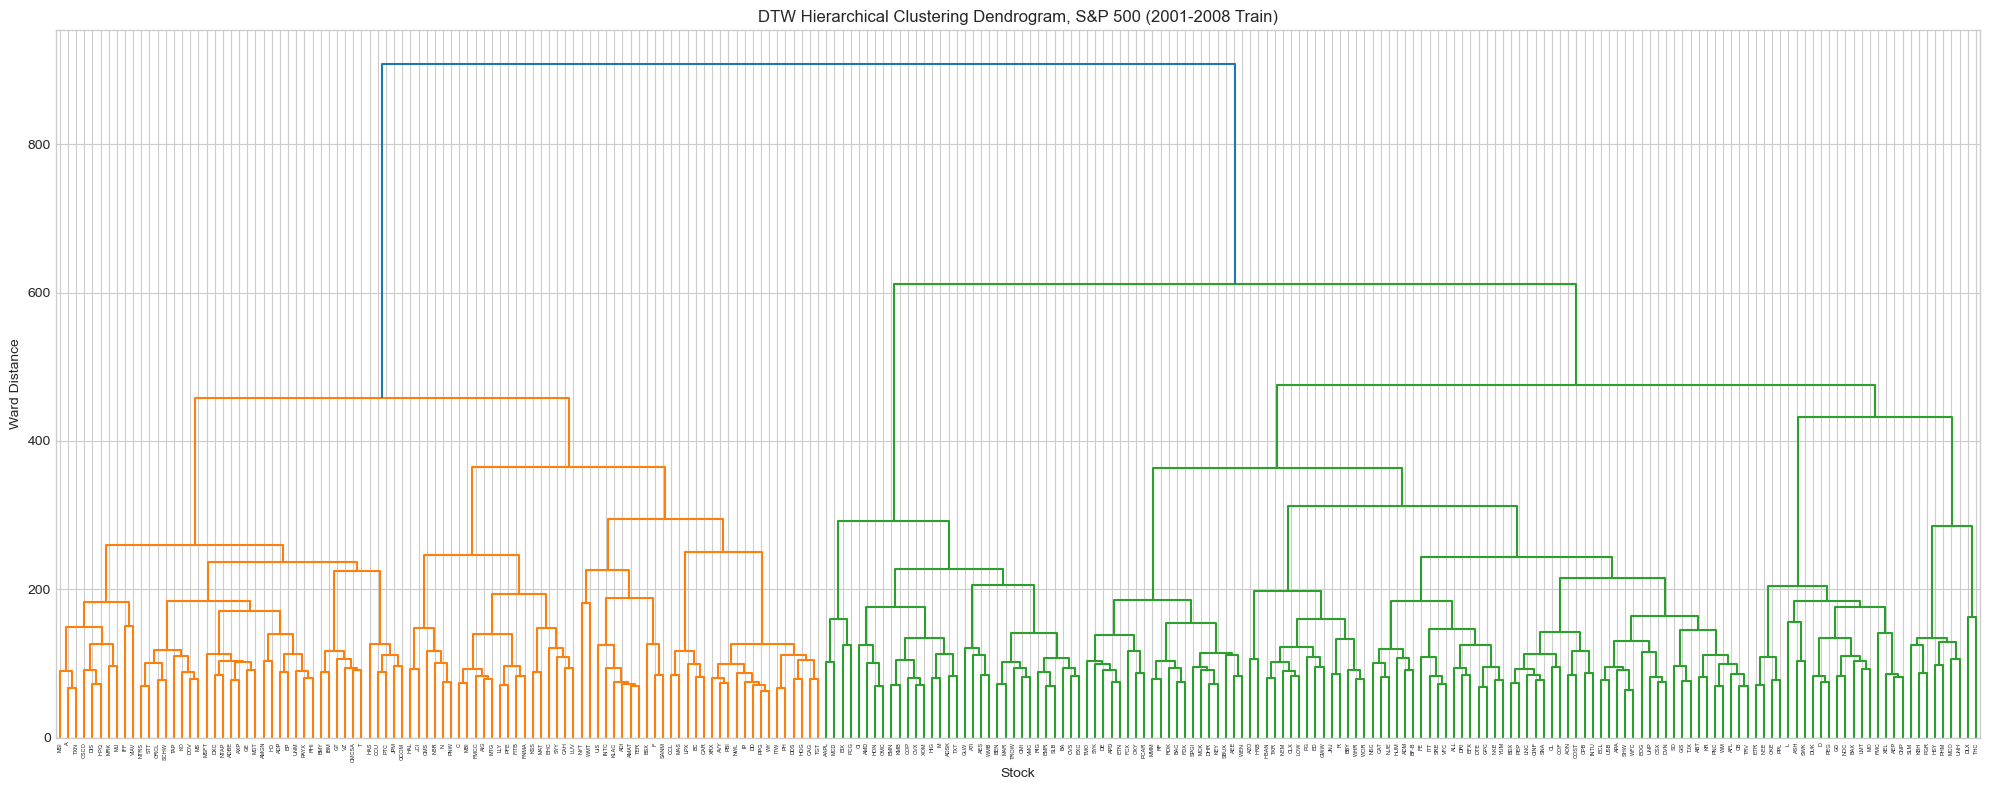

DTW Cluster Validation Summary:
   k                        sizes  silhouette  calinski_harabasz  \
0  2                    [94, 142]      0.1268            28.1867   
1  4             [94, 32, 82, 28]      0.0771            15.3315   
2  7  [43, 21, 30, 32, 82, 19, 9]      0.0714            12.6922   

   davies_bouldin  
0          2.7400  
1          3.4631  
2          2.7269  
Preferred k by index: {'silhouette': np.int64(2), 'calinski_harabasz': np.int64(2), 'davies_bouldin': np.int64(7)}


In [9]:
def cluster_and_validate(dist, name):
    link = linkage(squareform(dist, checks=False), method='ward')
    clusters, cvi = {}, []
    for k in K_VALUES:
        clusters[k] = fcluster(link, t=k, criterion='maxclust')
        sizes = pd.Series(clusters[k]).value_counts().sort_index().tolist()
        sil = silhouette_score(dist, clusters[k], metric='precomputed')
        ch  = calinski_harabasz_score(train_sharpe_data.T, clusters[k])
        db  = davies_bouldin_score(train_sharpe_data.T, clusters[k])
        cvi.append({'k': k, 'sizes': sizes, 'silhouette': sil,
                    'calinski_harabasz': ch, 'davies_bouldin': db})

    fig, ax = plt.subplots(figsize=(20, 8))
    dendrogram(link, labels=tickers, leaf_rotation=90, leaf_font_size=4, ax=ax)
    ax.set_title(f'{name} Hierarchical Clustering Dendrogram, S&P 500 '
                 f'({TRAIN_START[:4]}-{TRAIN_END[:4]} Train)')
    ax.set_xlabel('Stock'); ax.set_ylabel('Ward Distance')
    plt.tight_layout()
    plt.savefig(f'{name.lower()}_dendrogram_{TAG}.png', dpi=150, bbox_inches='tight')
    plt.show()

    df = pd.DataFrame({'ticker': tickers})
    for k in K_VALUES:
        df[f'cluster_k{k}'] = clusters[k]
    df.to_csv(f'{name.lower()}_cluster_assignments_{TAG}.csv', index=False)

    cvi_df = pd.DataFrame(cvi)
    print(f'{name} Cluster Validation Summary:')
    print(cvi_df)
    best = {'silhouette': cvi_df.loc[cvi_df['silhouette'].idxmax(), 'k'],
            'calinski_harabasz': cvi_df.loc[cvi_df['calinski_harabasz'].idxmax(), 'k'],
            'davies_bouldin': cvi_df.loc[cvi_df['davies_bouldin'].idxmin(), 'k']}
    print(f'Preferred k by index: {best}')
    return clusters, df, cvi_df

dtw_clusters, dtw_clusters_df, dtw_cvi_df = cluster_and_validate(dtw_distance_matrix, 'DTW')   

In [10]:
print(train_sharpe_data.shape)                                   # expect (418, 236)
print(train_sharpe_data.index[0].date(), train_sharpe_data.index[-1].date())   # expect 2001-01-03 to 2008-12-31
print('NaN:', train_sharpe_data.isna().sum().sum(), ' inf:', np.isinf(train_sharpe_data).sum().sum())   # expect 0 and 0
print(train_sharpe_data.stack().describe())                      # values should mostly fall between about -3 and +4

(418, 236)
2001-01-03 2008-12-31
NaN: 0  inf: 0
count   98648.0000
mean        0.2282
std         0.9611
min        -3.1290
25%        -0.4397
50%         0.2219
75%         0.8793
max         4.8208
dtype: float64


In [11]:
# OCP distance matrix (Train only): absolute-difference cost (Stübinger, 2019),
# causality constraint j >= i, computed in both directions, minimum taken
@njit(cache=True)
def _ocp_one_way(x, y):
    n, m = len(x), len(y)
    prev = np.full(m, np.inf)
    for i in range(n):
        cur = np.full(m, np.inf)
        for j in range(i, m):                   # OCP: only j >= i (causality constraint)
            if i == 0 and j == 0:
                cur[0] = abs(x[0] - y[0])
                continue
            best = np.inf
            if i > 0 and prev[j] < best:
                best = prev[j]
            if j > 0 and cur[j - 1] < best:
                best = cur[j - 1]
            if i > 0 and j > 0 and prev[j - 1] < best:
                best = prev[j - 1]
            cur[j] = abs(x[i] - y[j]) + best
        prev = cur
    return prev[m - 1]

@njit(parallel=True, cache=True)
def _ocp_matrix(X):
    n = X.shape[1]
    D = np.zeros((n, n))
    for i in prange(n):
        for j in range(i + 1, n):
            d = min(_ocp_one_way(X[:, i], X[:, j]), _ocp_one_way(X[:, j], X[:, i]))
            D[i, j] = d
            D[j, i] = d
    return D

t0 = time.time()
ocp_matrix = _ocp_matrix(X)
print(f'OCP distance matrix computed in {time.time()-t0:.1f} seconds, shape {ocp_matrix.shape}')
np.save(f'ocp_distance_matrix_{TAG}_train.npy', ocp_matrix)

OCP distance matrix computed in 24.4 seconds, shape (236, 236)


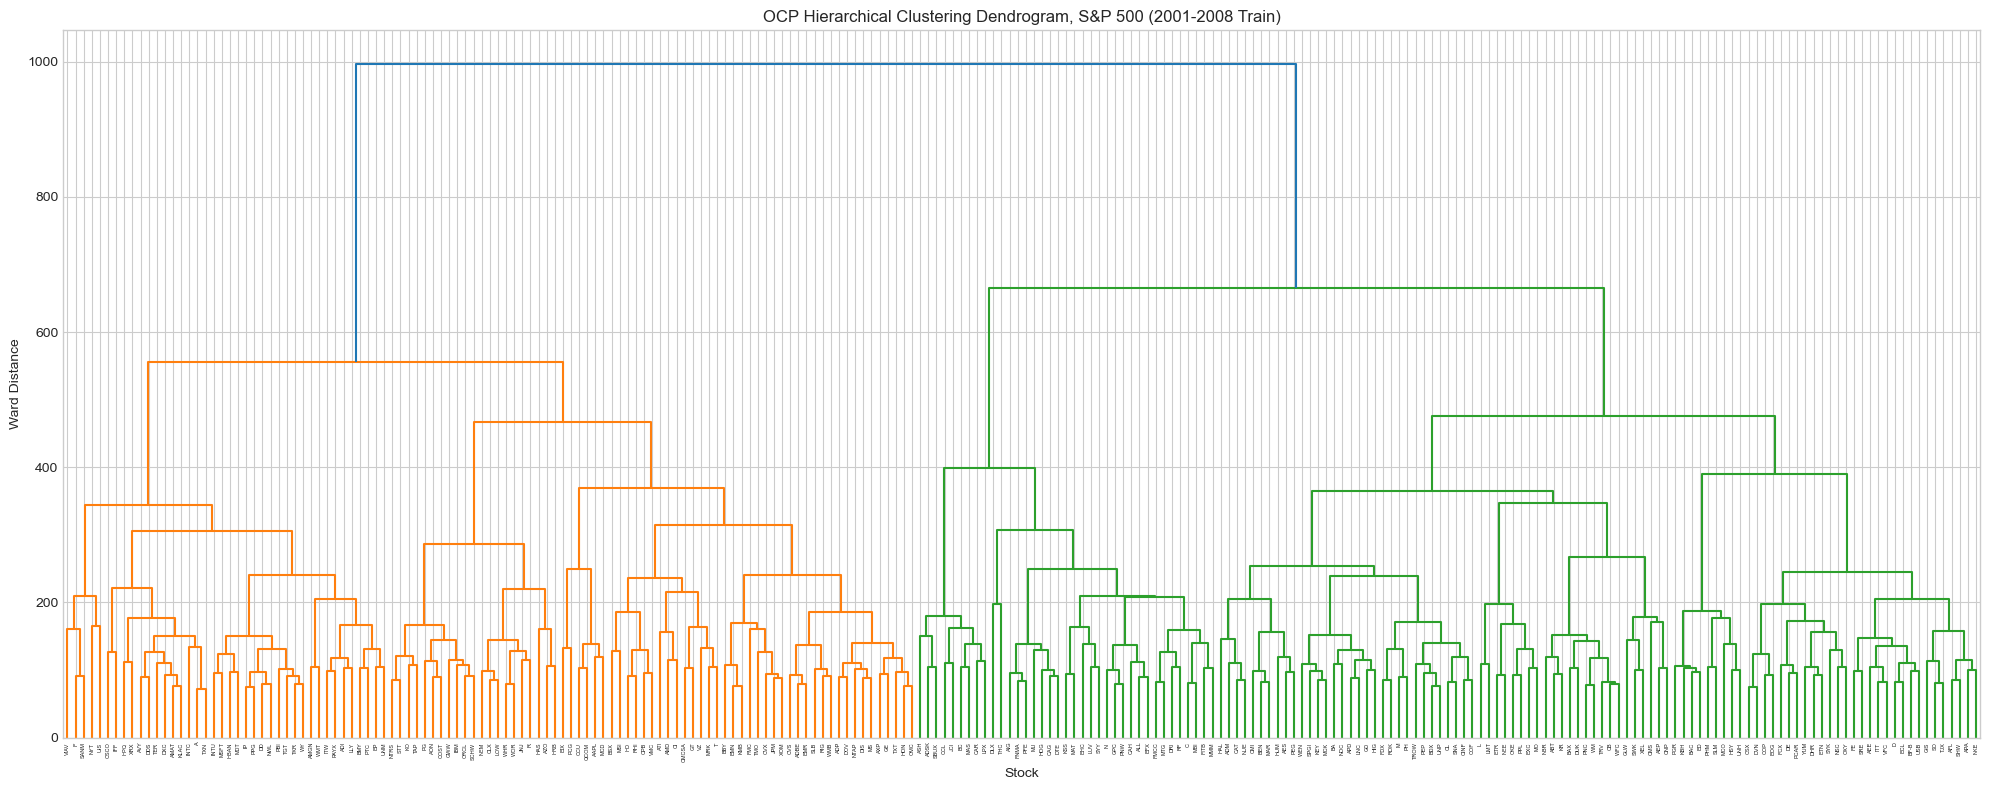

OCP Cluster Validation Summary:
   k                        sizes  silhouette  calinski_harabasz  \
0  2                   [105, 131]      0.1170            14.4819   
1  4             [40, 65, 37, 94]      0.0658            13.4903   
2  7  [40, 21, 44, 9, 28, 56, 38]      0.0476            10.2041   

   davies_bouldin  
0          3.8778  
1          3.5982  
2          3.2375  
Preferred k by index: {'silhouette': np.int64(2), 'calinski_harabasz': np.int64(2), 'davies_bouldin': np.int64(7)}


In [13]:
ocp_clusters, ocp_clusters_df, ocp_cvi_df = cluster_and_validate(ocp_matrix, 'OCP')

   k  ARI_DTW_vs_OCP
0  2          0.1687
1  4          0.1848
2  7          0.2255


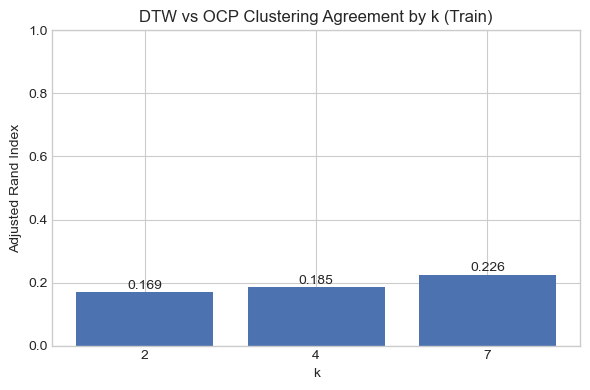

In [14]:
# DTW-OCP clustering agreement (Adjusted Rand Index) at each k
ari_df = pd.DataFrame([{'k': k, 'ARI_DTW_vs_OCP': adjusted_rand_score(dtw_clusters[k], ocp_clusters[k])}
                       for k in K_VALUES])
print(ari_df)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(ari_df['k'].astype(str), ari_df['ARI_DTW_vs_OCP'], color='#4c72b0')
for i, v in enumerate(ari_df['ARI_DTW_vs_OCP']):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center')
ax.set_ylim(0, 1); ax.set_xlabel('k'); ax.set_ylabel('Adjusted Rand Index')
ax.set_title('DTW vs OCP Clustering Agreement by k (Train)')
plt.tight_layout()
plt.savefig(f'ari_dtw_ocp_by_k_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()
ari_df.to_csv(f'ari_dtw_ocp_{TAG}.csv', index=False)

In [15]:
# Do DTW and OCP rank stock similarity the same way? (Spearman correlation of all pair distances)
from scipy.stats import spearmanr

iu = np.triu_indices(len(tickers), k=1)          # every unique pair (upper triangle, no diagonal)
rho = spearmanr(dtw_distance_matrix[iu], ocp_matrix[iu]).correlation
print(f'Spearman correlation between DTW and OCP distances: {rho:.3f} '
      f'({len(iu[0]):,} pairs)')

Spearman correlation between DTW and OCP distances: 0.885 (27,730 pairs)


In [16]:
train_price_data = price_data.loc[TRAIN_START:TRAIN_END]

def test_cointegration_within_clusters(clusters_df, prices, method_name, k_col=f'cluster_k{K_COINT}', alpha=0.05):
    rows = []
    for cid in sorted(clusters_df[k_col].unique()):
        members = clusters_df.loc[clusters_df[k_col] == cid, 'ticker'].tolist()
        for a in range(len(members)):
            for b in range(a + 1, len(members)):
                t1, t2 = members[a], members[b]
                _, p, _ = coint(np.log(prices[t1]), np.log(prices[t2]))
                rows.append({'method': method_name, 'cluster': cid,
                             'stock1': t1, 'stock2': t2, 'pvalue': p})
    df = pd.DataFrame(rows)
    rej, p_bh, _, _ = multipletests(df['pvalue'], alpha=alpha, method='fdr_bh')
    df['pvalue_bh'] = p_bh
    df['significant'] = rej
    print(f'{method_name}: {len(df):,} pairs tested, {df["significant"].sum()} significant after BH')
    return df

dtw_coint = test_cointegration_within_clusters(dtw_clusters_df, train_price_data, 'DTW')
ocp_coint = test_cointegration_within_clusters(ocp_clusters_df, train_price_data, 'OCP')
coint_all = pd.concat([dtw_coint, ocp_coint], ignore_index=True)
coint_all.to_csv(f'coint_results_{TAG}_train.csv', index=False)

selected = coint_all[coint_all['significant']].sort_values('pvalue_bh')
print(selected[['method', 'stock1', 'stock2', 'pvalue_bh']].to_string(index=False))

DTW: 5,572 pairs tested, 34 significant after BH
OCP: 4,593 pairs tested, 42 significant after BH
method stock1 stock2  pvalue_bh
   OCP    BBY   NTAP     0.0008
   OCP      A   PAYX     0.0041
   DTW      A   PAYX     0.0100
   OCP     CB     MO     0.0140
   OCP    DXC    XRX     0.0140
   OCP     CB    PEG     0.0140
   OCP    DRI    EFX     0.0140
   OCP    EMR    SLB     0.0140
   OCP    PEP   TROW     0.0140
   OCP     MO    PEP     0.0140
   OCP    DXC    PBI     0.0146
   OCP   CINF      M     0.0156
   OCP    DXC     WY     0.0174
   OCP    MDT    XRX     0.0174
   OCP     CB    PEP     0.0202
   OCP    PBI     WY     0.0202
   OCP    DHR    USB     0.0202
   OCP    AFL    APA     0.0207
   OCP    CMI    PEP     0.0207
   OCP    DIS    JPM     0.0228
   DTW    CLX    WFC     0.0233
   OCP   MSFT    TXN     0.0273
   OCP    LLY    TER     0.0294
   OCP    AVY    DDS     0.0294
   OCP    DOV    JPM     0.0294
   OCP     GD     MO     0.0294
   OCP    PEP     WM     0.0294
   OCP

In [17]:
print("""
    OCP clustering produced fewer within-cluster candidate pairs that DTW (4,593 vs. 5,572) 
    but a higher cointegration hit rate (0.91% vs. 0.61%), with 17 of the significant pairs 
    shared across methods.
""")


    OCP clustering produced fewer within-cluster candidate pairs that DTW (4,593 vs. 5,572) 
    but a higher cointegration hit rate (0.91% vs. 0.61%), with 17 of the significant pairs 
    shared across methods.

